# Team 3 submission — EO Spatial Split Planner

This is the modified `START_HERE.ipynb` submission notebook. It demonstrates an agent-callable MCP capability for choosing spatial separation, generating full-AOI patch datasets and reviewing model behavior on real Earth Observation data.

Run top to bottom in the project Python environment. The default uses cached real Sentinel-2/WorldCover pixels and previously trained CPU models, then makes an actual local MCP planning call. Set `TRAIN_MODELS=True` to retrain the three model conditions, or `RUN_LIVE_EVE=True` to repeat the optional network agent chain using the repository `.env`. No API keys are embedded or displayed. The exact recorded prompts, raw responses, machine verification and corrections appear below.

| Judging criterion | Weight | Evidence in this submission |
| --- | ---: | --- |
| Usefulness | 40% | B05-derived separation, full-AOI patch datasets, retained-area/distances and a real three-condition [segmentation comparison](examples/eo-spatial-split-planner/artifacts/segmentation_benchmark/segmentation_report.json) |
| Agent readiness | 30% | Four typed MCP tools, actual stdio/HTTP checks, hosted geocoding → actual satellite-raster evaluation → patch planning, plus the exact EVE prompt/response chain below |
| Quality | 20% | Seeded calculations, [upstream patch parity](examples/eo-spatial-split-planner/artifacts/patch_reference_validation.json), [variogram parity](examples/eo-spatial-split-planner/artifacts/reference_validation.json), geometric/quality tests and [validation evidence](examples/eo-spatial-split-planner/artifacts/validation_summary.json) |
| Demo | 10% | This executable notebook: real imagery/indices, cross-split-only guard maps, extracted arrays, predictions, metrics and reviewed EVE output |

The current live EVE replay uses the cached actual 2021 Sentinel-2 raster for evaluation and planning; it performs no CNN training or new remote imagery download. The matched-2021 WorldCover segmentation comparison runs separately on CPU. Earlier 2024 remote-acquisition evidence is historical. GIS MCP integration is a reviewed conditional handoff, not a connected or tested service in this account.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from IPython.display import Image, JSON, Markdown, display

_here=Path.cwd()
REPO_ROOT=next(p for p in [_here,_here / "agentic-eo",*_here.parents]
               if (p / "lib" / "agentic_eo").is_dir())
TOOL_ROOT=REPO_ROOT / "examples" / "eo-spatial-split-planner"
ARTIFACTS=TOOL_ROOT / "artifacts"
DATA_DIR=ARTIFACTS / "segmentation_data"
BENCHMARK_DIR=ARTIFACTS / "segmentation_benchmark"
sys.path.insert(0,str(TOOL_ROOT))
import server as planner
from run_segmentation import load_demo_data, run_demo


## MCP and the actual EVE agent question

The server is `examples/eo-spatial-split-planner/server.py`, exposing `evaluate_sentinel2_autocorrelation`, `evaluate_spatial_autocorrelation`, `plan_sentinel2_split` and `plan_spatial_split`. Its schemas and a real local tool call are exercised later in this notebook.

The optional live cell invokes the existing EVE test runner, which loads credentials from the repository `.env` and combines the local server with hosted geocoding. By default it replays the saved successful trace. Raw model prose is shown verbatim inside text blocks and is **not** treated as verified scientific interpretation; review notes and machine-computed tool reports govern numerical claims. A new live run requires fresh review of its prose.


In [2]:
RUN_LIVE_EVE=False
if RUN_LIVE_EVE:
    feature_path=DATA_DIR / "sentinel2_reflectance_20m.tif"
    if not feature_path.exists():
        from segmentation_data import fetch_segmentation_data
        fetch_segmentation_data(DATA_DIR)
    from test_eve import run_agent
    await run_agent(ARTIFACTS,raster_path=str(feature_path))
else:
    print("Replaying saved live EVE evidence; no network agent call requested.")

eve_evidence=json.loads((ARTIFACTS / "eve_demo.json").read_text())
SYSTEM_PROMPT=eve_evidence.get("system_prompt")
if SYSTEM_PROMPT is None:
    import ast
    source_tree=ast.parse((TOOL_ROOT / "test_eve.py").read_text())
    agent_function=next(node for node in ast.walk(source_tree)
                        if isinstance(node,ast.AsyncFunctionDef) and node.name=="run_agent")
    prompt_assignment=next(node for node in ast.walk(agent_function)
                           if isinstance(node,ast.Assign)
                           and any(isinstance(target,ast.Name) and target.id=="prompt" for target in node.targets))
    SYSTEM_PROMPT=ast.literal_eval(prompt_assignment.value)
EVE_QUERY=eve_evidence["query"]
display(Markdown("**Exact recorded system prompt**"))
print(SYSTEM_PROMPT)
turns=eve_evidence.get("agent_turns") or [{"query":EVE_QUERY,"answer":eve_evidence["answer"]}]
for number,turn in enumerate(turns,1):
    display(Markdown(f"**Exact user prompt — turn {number}**"))
    print(turn["query"])
    display(Markdown(f"**Raw recorded assistant response — turn {number}; see corrections below**"))
    display(Markdown("```text\n"+turn["answer"]+"\n```"))
display(JSON({"tested_at_utc":eve_evidence.get("tested_at_utc"),
              "model":eve_evidence.get("model"),
              "configuration_source":eve_evidence.get("configuration_source"),
              "verification":eve_evidence.get("verification"),
              "input_reference":eve_evidence.get("input_reference"),
              "review_notes":eve_evidence.get("review_notes",[])}))


Replaying saved live EVE evidence; no network agent call requested.


**Exact recorded system prompt**

You are an Earth Observation research assistant. Use the connected tools for every numerical result. Complete all three requested tool calls. Never invent pixels, statistics, an acquisition route, or test results. Use the exact AOI and dates requested, rather than a geocoder's larger bounding box. This chain uses geocoding, not a GIS viewer. Geometric separation and low single-band rho do not prove no data leakage. If a tool fails, report its error accurately. Keep the final answer under 200 words.


**Exact user prompt — turn 1**

Create a defensible spatial train/validation/test plan for the small study area [13.30,52.35,13.50,52.50] west,south,east,north. First identify its setting by calling reverse_geocode_place with latitude=52.425, longitude=13.40, zoom=10. Call evaluate_spatial_autocorrelation with raster_path='/private/tmp/eo-spatial-split-2021.tif', band_index=1, lag_m=2560, seed=3, n_pairs_per_lag=200000, n_bins=24, max_lag_m=12800. Then call plan_spatial_split with raster_path equal to the evaluator's artifacts.analysis_band path, band_index=1, buffer_m=null (or omit buffer_m for automatic guard), lag_m=2560, seed=3, patch_layout='reference_blocks', patch_size_pixels=[32,40], block_size_pixels=[96,120], edge_policy='extend', seed_candidates=200, and split_ratios=[0.7,0.1,0.2]. Omit n_patches. Randomize whole blocks in both spatial directions and extract fixed rectangular patches, following the checkpoint scripts/04_extract_patches.py workflow. Report requested versus realized fractions and the ranked 

**Raw recorded assistant response — turn 1; see corrections below**

```text
The study area is Berlin, Germany. The variogram analysis of the raster band at 2560 m lag shows a practical range of 521.49 m, with ρ = 0.042 (below the 0.1 threshold), meeting the independence criteria. The recommended buffer is 1298.24 m, which was applied symmetrically to the patch grid. The split plan used 32×40 pixel patches in 96×120 pixel blocks, with seed 104 selected for balanced retention. The realized fractions after buffering are 83.8% train, 9.5% validation, and 6.8% test. The minimum footprint gap between splits is 3191.72 m, exceeding the buffer. The paired unbuffered mask restores training patches while keeping validation/test heldouts fixed. Quality filtering discarded 6878 pixels, and the buffer removed an additional 366,178 candidate pixels. The geometric separation meets the requested guard, but class coverage remains unverified.
```

<IPython.core.display.JSON object>

## Matched-year satellite features and reference labels

The Berlin AOI is preserved. Features are calibrated surface reflectance in **B05, B03, B04 and B08**, on B05's native projected **20 m** grid. The 10 m bands are averaged to that grid; SCL is aligned by nearest neighbor, and only classes 4/5/6 are retained. ESA WorldCover 2021 v200 labels are aligned by nearest neighbor to the same grid and mapped to vegetation, built-up and water. Other labels are ignored.

WorldCover is a **weak annual reference**, produced by a classifier using Sentinel-1 and Sentinel-2. These scores measure agreement with that reference, not independently surveyed accuracy. Annual labels may also differ from the land cover on the acquisition date.

`RECOMPUTE_IMAGES=False` reuses the saved numeric GeoTIFFs; missing inputs trigger real public-STAC acquisition. `TRAIN_MODELS=False` replays actual saved training results; set it to `True` to retrain all conditions from cached imagery without pretrained weights.


## How checkpoint scripts 00–04 map to this demo

| Checkpoint stage | Reference workflow | What this notebook actually does |
| --- | --- | --- |
| [00_select_aoi.py](https://github.com/stefanopitton/lulc-classification/blob/ac7dfc6578c2c408c87398e15073354752bbd32b/scripts/00_select_aoi.py) | Compare candidate AOIs and seasonal scene availability | Uses the stated Berlin AOI; does not claim to have rerun the full candidate survey |
| [01_download_sentinel2.py](https://github.com/stefanopitton/lulc-classification/blob/ac7dfc6578c2c408c87398e15073354752bbd32b/scripts/01_download_sentinel2.py) | Acquire multiband scenes per season on one aligned grid | Uses the recorded real 2021 scene, four calibrated bands and SCL masking through Planetary Computer |
| [02_create_seasonal_composite.py](https://github.com/stefanopitton/lulc-classification/blob/ac7dfc6578c2c408c87398e15073354752bbd32b/scripts/02_create_seasonal_composite.py) | Cloud-mask and median-composite each season; stack spectral bands and indices | Computes real single-scene NDVI/NDWI below; full seasonal acquisition/median compositing is optional and not executed here, and no 52-channel seasonal stack is claimed |
| [03_download_world_cover.py](https://github.com/stefanopitton/lulc-classification/blob/ac7dfc6578c2c408c87398e15073354752bbd32b/scripts/03_download_world_cover.py) | Mosaic/reproject WorldCover to the feature grid, record mapping and class stats | Uses aligned 2021 WorldCover and explicitly groups the available labels into three model classes |
| [04_extract_patches.py](https://github.com/stefanopitton/lulc-classification/blob/ac7dfc6578c2c408c87398e15073354752bbd32b/scripts/04_extract_patches.py) | Assign blocks, select a class-covering seed, buffer the fixed patch grid, export arrays/metadata/train-only stats | Executes the local adaptation below with rectangular axes, quality filtering and paired exports; records the frozen source and adaptations |

The upstream configuration's example seasonal dates are 2022 while its WorldCover year is 2021. This demo keeps imagery and labels in 2021. Adopting the full pipeline requires an explicit matched-year seasonal configuration and its extra acquisition/processing, rather than treating a single scene as a seasonal median.


In [3]:
RECOMPUTE_IMAGES=False
TRAIN_MODELS=False
BBOX=[13.30,52.35,13.50,52.50]
START_DATE,END_DATE="2021-06-01","2021-08-31"
BAND="B05"
SPLIT_SEED,MODEL_SEED=3,42
SPLIT_RATIOS=[0.7,0.1,0.2]  # train, validation, test
PATCH_LAYOUT="reference_blocks"
PATCH_SIZE_PIXELS=[32,40]
BLOCK_SIZE_PIXELS=[96,120]
EDGE_POLICY="extend"  # cover the full AOI; clip terminal patches rather than trim image strips
SEED_CANDIDATES=200
MAX_NAN_FRACTION=0.5
REQUIRE_CLASS_COVERAGE=True  # offline extraction uses available reference classes
TRAINING_STEPS=150
TRAINING_CROP_SIZE=16
BUFFER_M=None
VARIOGRAM_OPTIONS={"n_bins":24,"n_pairs_per_lag":200_000,"max_lag_m":12_800.0}
CONDITION_LABELS={
    "without_buffer":"without training erosion (fixed eroded held-outs)",
    "with_buffer":"with symmetric training erosion",
    "size_matched_without_buffer":"size-matched, without training erosion",
}

expected_inputs=[DATA_DIR / name for name in (
    "sentinel2_reflectance_20m.tif","worldcover_2021_20m.tif","manifest.json")]
if RECOMPUTE_IMAGES or not all(p.exists() for p in expected_inputs):
    from segmentation_data import fetch_segmentation_data
    fetch_segmentation_data(DATA_DIR,bbox=BBOX,start_date=START_DATE,end_date=END_DATE,
                            force=RECOMPUTE_IMAGES)
values,labels,profile,resolution_m,manifest=load_demo_data(DATA_DIR)
feature_path=DATA_DIR / "sentinel2_reflectance_20m.tif"
display(JSON({"request":manifest["request"],"shape":manifest["shape"],
              "bands":manifest["band_names"],"pixel_size_m":resolution_m,
              "sentinel2":manifest["sentinel2"],"worldcover":manifest["worldcover"],
              "label_caveat":manifest["label_caveat"],
              "patch_settings":{"layout":PATCH_LAYOUT,"patch_size_pixels":PATCH_SIZE_PIXELS,
                  "block_size_pixels":BLOCK_SIZE_PIXELS,"edge_policy":EDGE_POLICY,
                  "split_ratios":SPLIT_RATIOS,
                  "seed_candidates":SEED_CANDIDATES,"max_nan_fraction":MAX_NAN_FRACTION,
                  "require_class_coverage":REQUIRE_CLASS_COVERAGE}}))


<IPython.core.display.JSON object>

## A real single-scene adaptation of preprocessing stage 02

Compute NDVI from B08/B04 and NDWI from B03/B08, using finite inputs and nonzero denominators. These are single-scene indices on the aligned 20 m grid, not seasonal median composites. NDBI requires SWIR, which is absent from the cached four-band data. The CNN still receives the four reflectance bands, and the spatial estimate still uses raw B05.


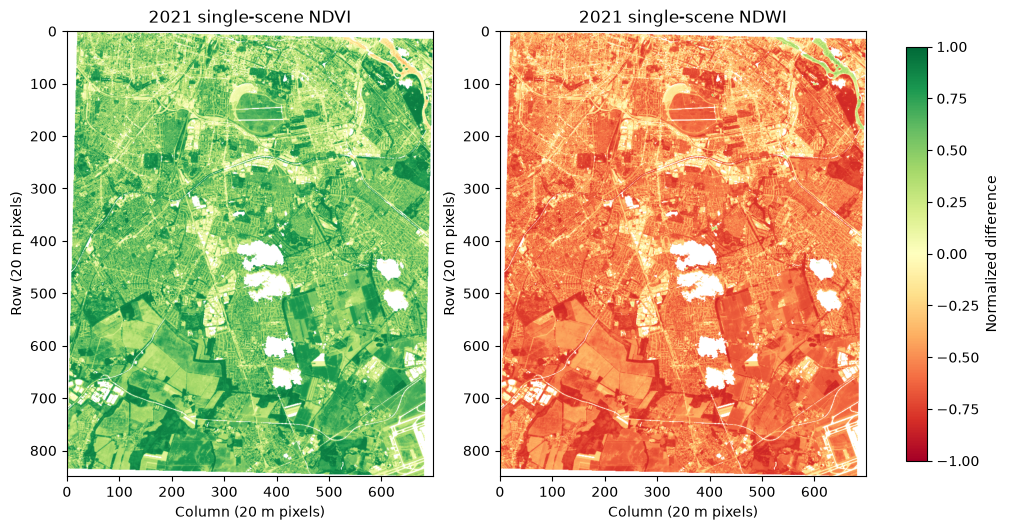

<IPython.core.display.JSON object>

In [4]:
band_position={name:i for i,name in enumerate(manifest["band_names"])}
green=values[band_position["B03"]]
red=values[band_position["B04"]]
nir=values[band_position["B08"]]
def finite_normalized_difference(first,second):
    denominator=first+second
    result=np.full(first.shape,np.nan,dtype=np.float32)
    valid=np.isfinite(first)&np.isfinite(second)&(denominator!=0)
    np.divide(first-second,denominator,out=result,where=valid)
    return result
single_scene_indices={"NDVI":finite_normalized_difference(nir,red),
                      "NDWI":finite_normalized_difference(green,nir)}
fig,axes=plt.subplots(1,2,figsize=(10,6),layout="constrained")
for ax,(name,index) in zip(axes,single_scene_indices.items()):
    shown=ax.imshow(np.ma.masked_invalid(index),cmap="RdYlGn",vmin=-1,vmax=1)
    ax.set(title=f"2021 single-scene {name}",xlabel="Column (20 m pixels)",ylabel="Row (20 m pixels)")
fig.colorbar(shown,ax=axes,label="Normalized difference",shrink=.7)
plt.show()
display(JSON({name:{"finite_pixels":int(np.isfinite(index).sum()),
    "minimum":float(np.nanmin(index)),"maximum":float(np.nanmax(index))}
    for name,index in single_scene_indices.items()}))


## Fixed patch grid, random block assignment and symmetric buffering

The checkpoint divides a raster into a fixed patch grid and assigns **blocks of patches** to train/validation/test. This adapter preserves those operations while allowing rectangular patches/blocks and **full-AOI coverage**. With `EDGE_POLICY="extend"`, the last block in each axis extends to the raster boundary instead of trimming an image strip. The full 850 × 699 image has a 27 × 18 patch grid; terminal patches are clipped to the actual source extent (18 pixels high and/or 19 wide). There is no bottom/right crop band. Nodata and quality-rejected patches remain excluded for their recorded reasons.

The configured 32 × 40-pixel patches and nominal 96 × 120-pixel groups use an 8 × 5 assignment grid: 40 randomly assigned groups, with three patches per axis in regular interior groups. Terminal blocks are larger than the nominal size so all source pixels remain within the assignment. An explicit legacy crop policy can reproduce the earlier complete-block support; the default notebook uses extension.

For each axis, the upstream reference radius is `ceil(buffer_m / (patch_size_pixels * resolution_m))`. The adapter records both reference and applied radii; it can increase an applied radius to preserve the conservative pixel/patch-footprint gap when inactive cells interrupt a two-sided interface. Inactive cells still do not count as another split. Only quality-eligible patches with a **different train/validation/test split label** within that row/column neighborhood trigger exclusion. Same-split patch seams, the AOI boundary, nodata holes and quality-rejected cells do not trigger buffers. They are excluded support, not extra split labels. **Both sides of a split boundary are eroded.** Quantization and symmetric erosion can make the actual gap much larger than the requested distance; inspect the measured cross-split gaps rather than treating the input as the final gap.

As in upstream `select_seed`, candidate assignment seeds 0–199 are ranked by retained split support and checked for class coverage. This offline demo requires every available model class in each retained split after quality filtering. It therefore uses reference-class information to select a split, and that choice is disclosed. `SPLIT_SEED=3` controls the variogram; it is not necessarily the selected assignment seed. Requested split ratios describe block-allocation targets; rounding, masking, class coverage and erosion affect retained proportions. The 40 groups realize the requested allocation exactly before filtering: 28 train, 4 validation and 8 test groups. Extended terminal groups have different areas, and quality filtering/buffering changes the realized patch and pixel proportions.

The raw block-label grid shows assignment before filtering. The candidate-pixel mask then shows quality-eligible patches before symmetric erosion; rejected patches and invalid pixels are already excluded. The paired model baseline restores **training patches only** while keeping the buffered validation/test locations fixed. It can already have a substantial one-sided guard. The raw candidate mask has different held-out support and is shown for inspection, not used as an interchangeable model-evaluation baseline.


In [5]:
report_path=BENCHMARK_DIR / "segmentation_report.json"
if TRAIN_MODELS or not report_path.exists():
    segmentation_report=run_demo(
        data_dir=DATA_DIR,output_dir=BENCHMARK_DIR,buffer_m=BUFFER_M,
        split_seed=SPLIT_SEED,model_seed=MODEL_SEED,steps=TRAINING_STEPS,crop_size=TRAINING_CROP_SIZE,
        max_pairs_per_lag=VARIOGRAM_OPTIONS["n_pairs_per_lag"],
        patch_layout=PATCH_LAYOUT,patch_size_pixels=PATCH_SIZE_PIXELS,
        block_size_pixels=BLOCK_SIZE_PIXELS,edge_policy=EDGE_POLICY,split_ratios=SPLIT_RATIOS,
        seed_candidates=SEED_CANDIDATES,max_nan_fraction=MAX_NAN_FRACTION,
        require_class_coverage=REQUIRE_CLASS_COVERAGE,
    )
else:
    segmentation_report=json.loads(report_path.read_text())
patch_plan=json.loads((BENCHMARK_DIR / "benchmark_plan.json").read_text())
LAG_M=float(segmentation_report["buffer_m"])
with rasterio.open(BENCHMARK_DIR / "candidate_patch_split.tif") as src:
    candidate_mask=src.read(1)
with rasterio.open(BENCHMARK_DIR / "unbuffered_patch_split.tif") as src:
    unbuffered_mask=src.read(1)
with rasterio.open(BENCHMARK_DIR / "buffered_patch_split.tif") as src:
    buffered_mask=src.read(1)
plan_summary={key:patch_plan[key] for key in (
    "method","patch_layout","seed","selected_seed","split_seed","autocorrelation_seed",
    "patch_size_pixels","block_size_pixels","block_labels","patch_label_grid",
    "buffer_radius","reference_buffer_radius_patches","buffer_radius_patches",
    "buffer_radii_patches","buffer_scope","buffer_interface_policy",
    "buffer_not_applied_to","crop",
    "grid_shape","block_grid_shape","patch_grid_shape","supported_raster_shape","supported_window","edge_policy","terminal_patch_shape",
    "edge_discarded_pixel_count","edge_discarded_valid_pixel_count","quality_rejected_patch_count",
    "class_coverage_required","class_coverage_complete","class_pixel_counts",
    "requested_block_split_ratios","realized_block_split_ratios",
    "realized_candidate_patch_split_ratios","realized_buffered_patch_split_ratios",
    "realized_paired_unbuffered_patch_split_ratios",
    "requested_split_ratios","n_candidate_patches","patch_counts",
    "requested_buffer_m","recommended_buffer_m","buffer_source","paired_comparison",
    "class_coverage","buffer_autocorrelation","splits","spatial_diagnostics",
    "unbuffered_baseline","reference_implementation","reference_patch_procedure","warnings") if key in patch_plan}
seed_search=patch_plan.get("seed_search",{})
plan_summary["seed_search"]={key:value for key,value in seed_search.items() if key!="candidates"}
plan_summary["seed_search"]["selected_candidate"]=next((row for row in seed_search.get("candidates",[])
    if row["seed"]==patch_plan.get("selected_seed")),None)
plan_summary["full_AOI_extent_retained"]=list(patch_plan["supported_raster_shape"])==list(values.shape[1:])
display(JSON(plan_summary))


<IPython.core.display.JSON object>

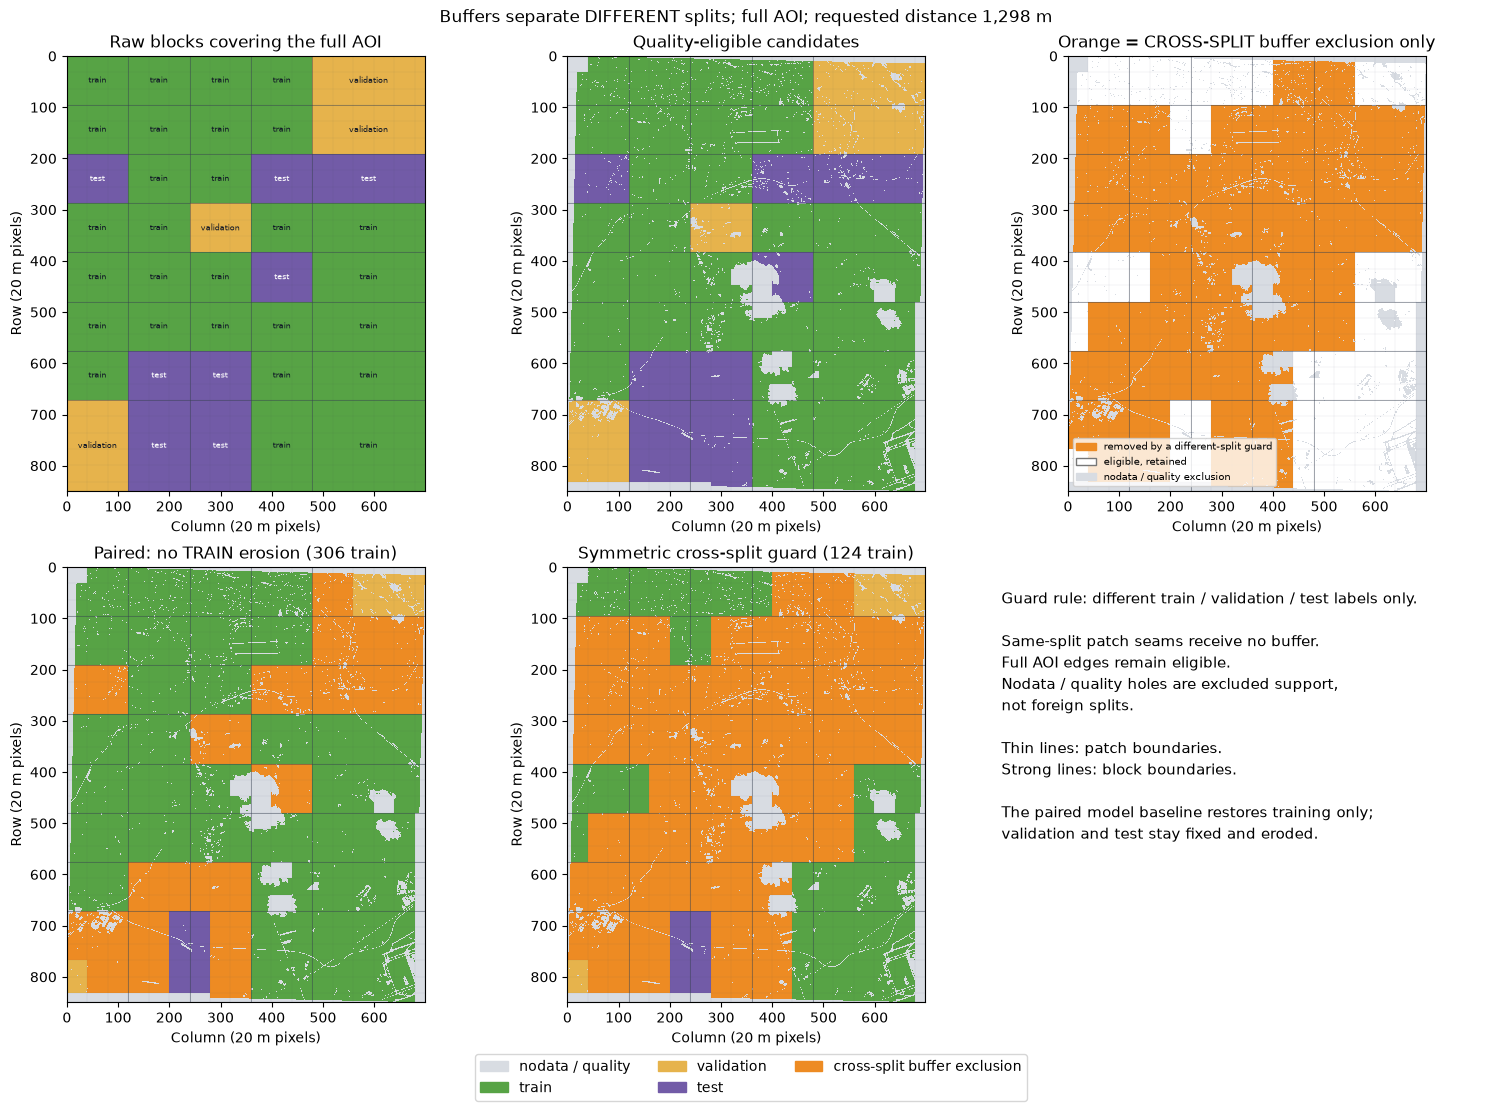

<IPython.core.display.JSON object>

In [6]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

split_palette=ListedColormap(["#d8dce2","#57a345","#e6b34c","#725ba7"])
overlay_palette=ListedColormap([*split_palette.colors,"#ed8b23"])
train_counts={name:result["training_patch_count"] for name,result in segmentation_report["conditions"].items()}
buffer_removed=(candidate_mask>0)&(buffered_mask==0)
guard_categories=np.zeros(candidate_mask.shape,dtype=np.uint8)
guard_categories[candidate_mask>0]=1
guard_categories[buffer_removed]=2
guard_palette=ListedColormap(["#d8dce2","#ffffff","#ed8b23"])
fig,axes=plt.subplots(2,3,figsize=(15,11),layout="constrained")
block_labels=np.asarray(patch_plan["block_labels"])
support_height,support_width=patch_plan["supported_raster_shape"]
block_height,block_width=BLOCK_SIZE_PIXELS
block_rows=[row*block_height for row in range(block_labels.shape[0])]+[support_height]
block_cols=[col*block_width for col in range(block_labels.shape[1])]+[support_width]
raw_assignment=np.zeros(candidate_mask.shape,dtype=np.uint8)
for (row,col),code in np.ndenumerate(block_labels):
    raw_assignment[block_rows[row]:block_rows[row+1],block_cols[col]:block_cols[col+1]]=code
axes[0,0].imshow(raw_assignment,cmap=split_palette,norm=BoundaryNorm(np.arange(-.5,4.5),4),interpolation="nearest")
for (row,col),code in np.ndenumerate(block_labels):
    axes[0,0].text((block_cols[col]+block_cols[col+1]-1)/2,(block_rows[row]+block_rows[row+1]-1)/2,
                   {1:"train",2:"validation",3:"test"}[int(code)],ha="center",va="center",
                   fontsize=6,color="white" if int(code)==3 else "#111827")
axes[0,0].set(title="Raw blocks covering the full AOI",xlabel="Column (20 m pixels)",ylabel="Row (20 m pixels)")
image_panels=[(axes[0,1],candidate_mask,"Quality-eligible candidates"),
              (axes[1,0],unbuffered_mask,f"Paired: no TRAIN erosion ({train_counts['without_buffer']} train)"),
              (axes[1,1],buffered_mask,f"Symmetric cross-split guard ({train_counts['with_buffer']} train)")]
for ax,mask,title in image_panels:
    display_mask=mask.copy()
    display_mask[(candidate_mask>0)&(mask==0)]=4  # display-only guard overlay; exported masks keep codes 0..3
    ax.imshow(display_mask,cmap=overlay_palette,norm=BoundaryNorm(np.arange(-.5,5.5),5),interpolation="nearest")
    ax.set(title=title,xlabel="Column (20 m pixels)",ylabel="Row (20 m pixels)")
axes[0,2].imshow(guard_categories,cmap=guard_palette,
                 norm=BoundaryNorm(np.arange(-.5,3.5),3),interpolation="nearest")
axes[0,2].set(title="Orange = CROSS-SPLIT buffer exclusion only",xlabel="Column (20 m pixels)",ylabel="Row (20 m pixels)")
axes[0,2].legend(handles=[Patch(color="#ed8b23",label="removed by a different-split guard"),
                         Patch(facecolor="white",edgecolor="#777777",label="eligible, retained"),
                         Patch(color="#d8dce2",label="nodata / quality exclusion")],
                  loc="lower left",fontsize=7)
patch_height,patch_width=PATCH_SIZE_PIXELS
block_height,block_width=BLOCK_SIZE_PIXELS
for ax in [axes[0,0],axes[0,1],axes[0,2],axes[1,0],axes[1,1]]:
    for row in [*range(0,support_height,patch_height),support_height]:
        ax.plot([-.5,support_width-.5],[row-.5,row-.5],color="#4b5563",linewidth=.15,alpha=.3)
    for col in [*range(0,support_width,patch_width),support_width]:
        ax.plot([col-.5,col-.5],[-.5,support_height-.5],color="#4b5563",linewidth=.15,alpha=.3)
    for row in block_rows:
        ax.plot([-.5,support_width-.5],[row-.5,row-.5],color="#374151",linewidth=.6,alpha=.55)
    for col in block_cols:
        ax.plot([col-.5,col-.5],[-.5,support_height-.5],color="#374151",linewidth=.6,alpha=.55)
axes[1,2].axis("off")
axes[1,2].text(0,.95,
    "Guard rule: different train / validation / test labels only.\n\n"
    "Same-split patch seams receive no buffer.\n"
    "Full AOI edges remain eligible.\nNodata / quality holes are excluded support,\nnot foreign splits.\n\n"
    "Thin lines: patch boundaries.\nStrong lines: block boundaries.\n\n"
    "The paired model baseline restores training only;\nvalidation and test stay fixed and eroded.",
    va="top",transform=axes[1,2].transAxes,fontsize=11,linespacing=1.4)
legend=[Patch(color=overlay_palette.colors[i],label=name) for i,name in enumerate((
    "nodata / quality","train","validation","test","cross-split buffer exclusion"))]
fig.legend(handles=legend,loc="outside lower center",ncol=3)
fig.suptitle(f"Buffers separate DIFFERENT splits; full AOI; requested distance {LAG_M:,.0f} m")
fig.savefig(BENCHMARK_DIR / "patch_split_layout.png",dpi=140)
plt.show()
display(JSON({"finite_candidate_pixels_removed_by_cross_split_buffer":int(buffer_removed.sum()),
              "paired_validation_pixel_locations_identical":bool(np.array_equal(unbuffered_mask==2,buffered_mask==2)),
              "paired_test_pixel_locations_identical":bool(np.array_equal(unbuffered_mask==3,buffered_mask==3)),
              "buffered_train_is_subset":bool(np.all((buffered_mask!=1)|(unbuffered_mask==1))),
              "raw_candidate_mask_role":"quality-eligible candidates before cross-split guard; its heldout support differs from the paired experiment"}))


## Inspect the extracted patch datasets

The extraction writes feature/label `.npy` arrays for both paired conditions, along with `patches_metadata.json` and `normalization_params.json`. Metadata records split assignment, seed search/class coverage, patch coordinates, keep masks, channel names and class counts. Shapes and labels are inspected from the actual archive below.

Following script 04, normalization statistics sample 25% of **training pixels only** with RNG seed 3 and include the 1st/99th percentiles, median, mean and standard deviation. These exported summary statistics are separate from the CNN's explicitly reported training-only z-score fit. Ignored labels and rejected-patch metadata are handled explicitly by the adaptation.


In [7]:
import io
import zipfile

patch_export=segmentation_report.get("patch_export",patch_plan.get("patch_export"))
if patch_export is None:
    raise RuntimeError("The reference-block extraction did not record patch_export.")
display(JSON(patch_export))
def exported_path(value):
    value=Path(value)
    return value if value.is_absolute() else BENCHMARK_DIR / value

for condition,export in patch_export["conditions"].items():
    archive_path=exported_path(export["archive_path"])
    with zipfile.ZipFile(archive_path) as archive:
        array_names=[name for name in archive.namelist() if name.endswith(".npy")]
        previews=[]
        for name in sorted(array_names)[:4]:
            array=np.load(io.BytesIO(archive.read(name)),allow_pickle=False)
            previews.append({"file":name,"shape":list(array.shape),"dtype":str(array.dtype)})
    metadata=json.loads(exported_path(export["metadata_path"]).read_text())
    normalization=json.loads(exported_path(export["normalization_path"]).read_text())
    display(JSON({"condition":condition,"array_file_count":len(array_names),
                  "array_previews":previews,"metadata_fields":list(metadata),
                  "normalization":normalization}))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## Variogram procedure

The AOI is one realization of a random field. Use the continuous values as read, without normalization, and calculate float64 population variance over finite pixels. Zero or non-finite variance is invalid.

Build 24 logarithmic bins from the native resolution to 12,800 m, using geometric centers. Draw 200,000 offsets per source bin with uniform angle and uniform radius inside that bin. Round to integer pixel offsets, discard zero offsets, and **reassign every pair to the bin containing its actual rounded distance**. Draw anchors uniformly over the raster; discard out-of-bounds partners and pairs touching non-finite values. Thus accepted counts vary by bin and need not equal the number of attempted draws.

For each destination bin, accumulate counts and squared differences in float64:

\[
\gamma(h) = \frac{\sum (z_i-z_j)^2}{2\,n_h},\qquad
\rho(h) = 1 - \frac{\gamma(h)}{\operatorname{var}(z)}.
\]

Empty bins remain missing. Negative rho values are retained. Fit only the spherical model to at least four populated bins, with nonnegative coefficients and `sigma = 1/sqrt(counts)`:

\[
\gamma_{\mathrm{sph}}(h) = c_0 + c_1(1.5t-0.5t^3),\qquad
 t=\min(h/a,1).
\]

`c0` is nugget, `c1` is partial sill, **total sill is `c0+c1`**, and `a` is practical range. Report residual sum of squares. The upstream reference names its second model coefficient `sill`; this tool distinguishes partial and total sill explicitly. No directional Pearson, covariance curve, Moran's I, Geary's C or exponential model is computed.


## Evaluate the measured lag on the actual B05 pixels

The requested lag below is the guard selected from this 2021 scene. The variogram uses the full 850 × 699 field, and the default extended layout keeps that full image extent for extraction as well. B05 occupies band 1 of the four-band feature GeoTIFF. Rho is interpolated linearly in **log-distance**, after excluding empty bins. Acceptance requires **`rho_at_lag < 0.1` AND `lag_m >= practical_range_m`** with a resolved spherical fit.

`buffer_autocorrelation` in a split report checks the actual guard separately from an optional query lag. A passing query at a larger separation cannot endorse a smaller guard.


In [8]:
evaluation=planner.evaluate_spatial_autocorrelation(
    raster_path=str(feature_path),band_index=1,band=BAND,lag_m=LAG_M,
    seed=SPLIT_SEED,**VARIOGRAM_OPTIONS)
if evaluation.get("status")!="ok":
    raise RuntimeError(evaluation.get("error",evaluation))
summary_keys=("estimator","lag_m","rho_at_lag","practical_range_m","nugget","partial_sill",
              "sill","fit_rss","fit_status","variance","nan_fraction","seed",
              "n_pairs_per_lag","decision","warnings")
display(JSON({key:evaluation[key] for key in summary_keys if key in evaluation}))
display(JSON({"per_bin_diagnostics":[
    {"lag_lo_m":lo,"lag_hi_m":hi,"lag_center_m":h,"valid_pair_count":n,"gamma":g,"rho":r}
    for lo,hi,h,n,g,r in zip(evaluation["lag_edges_m"][:-1],evaluation["lag_edges_m"][1:],
                            evaluation["lag_centers_m"],evaluation["counts"],
                            evaluation["gamma"],evaluation["rho"])]}))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

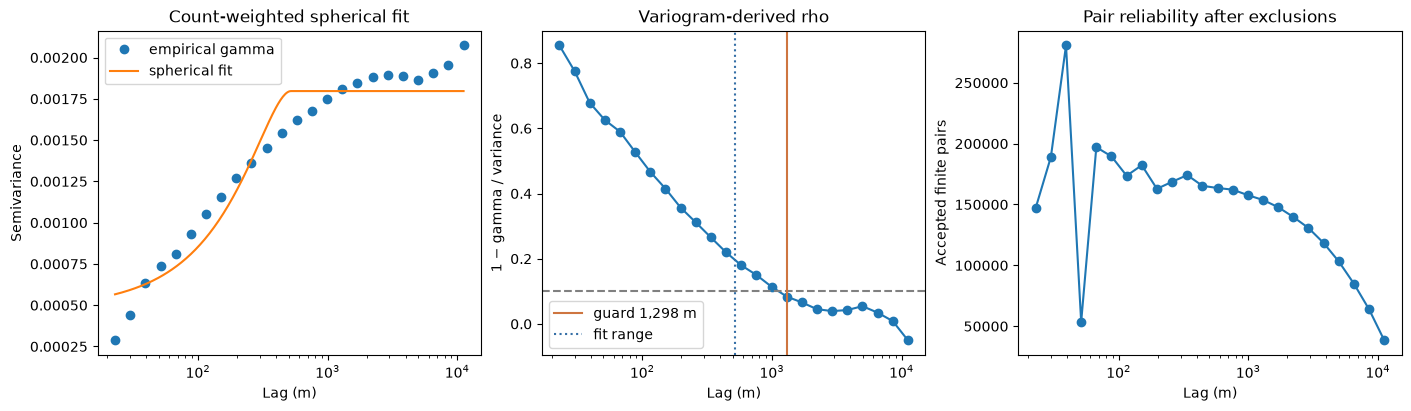

In [9]:
from core import spherical_variogram
centers=np.asarray(evaluation["lag_centers_m"],dtype=float)
gamma=np.asarray([np.nan if x is None else x for x in evaluation["gamma"]])
rho=np.asarray([np.nan if x is None else x for x in evaluation["rho"]])
fig,axes=plt.subplots(1,3,figsize=(14,4),layout="constrained")
axes[0].semilogx(centers,gamma,"o",label="empirical gamma")
model_lags=np.geomspace(centers[0],centers[-1],300)
axes[0].semilogx(model_lags,spherical_variogram(model_lags,evaluation["nugget"],
    evaluation["partial_sill"],evaluation["practical_range_m"]),label="spherical fit")
axes[0].set(xlabel="Lag (m)",ylabel="Semivariance",title="Count-weighted spherical fit")
axes[0].legend()
axes[1].semilogx(centers,rho,"o-")
axes[1].axhline(.1,color="gray",linestyle="--")
axes[1].axvline(LAG_M,color="#ce7540",label=f"guard {LAG_M:,.0f} m")
axes[1].axvline(evaluation["practical_range_m"],color="#356fa6",linestyle=":",label="fit range")
axes[1].set(xlabel="Lag (m)",ylabel="1 − gamma / variance",title="Variogram-derived rho")
axes[1].legend()
axes[2].semilogx(centers,evaluation["counts"],"o-")
axes[2].set(xlabel="Lag (m)",ylabel="Accepted finite pairs",title="Pair reliability after exclusions")
plt.show()


## Simple segmentation model and training controls

The model has three 3 × 3 convolutional layers with 16 channels and ReLU, then a 1 × 1 convolution producing three class logits (**5,283 trainable parameters**). It is trained from scratch on CPU with AdamW, learning rate 0.003, weight decay 0.0001, batch size 8, and fixed 16 × 16 crops for 150 optimizer steps. Each crop stays inside a training rectangle. All conditions start from the same seed-42 weights and use the same training budget.

Normalization is fitted separately on each condition's finite, labelled **training pixels only**. Validation is checked every 25 steps; the highest validation mean IoU selects the checkpoint, with the earliest tie. Each selected model is then tested once on the shared held-out test pixels. Class identities and model scores are not used to choose patch geometry or the variogram buffer; source-availability masks are already part of the cached input validity. There is no class weighting, pretrained model, test-set tuning or score-dependent buffer search.


<IPython.core.display.JSON object>

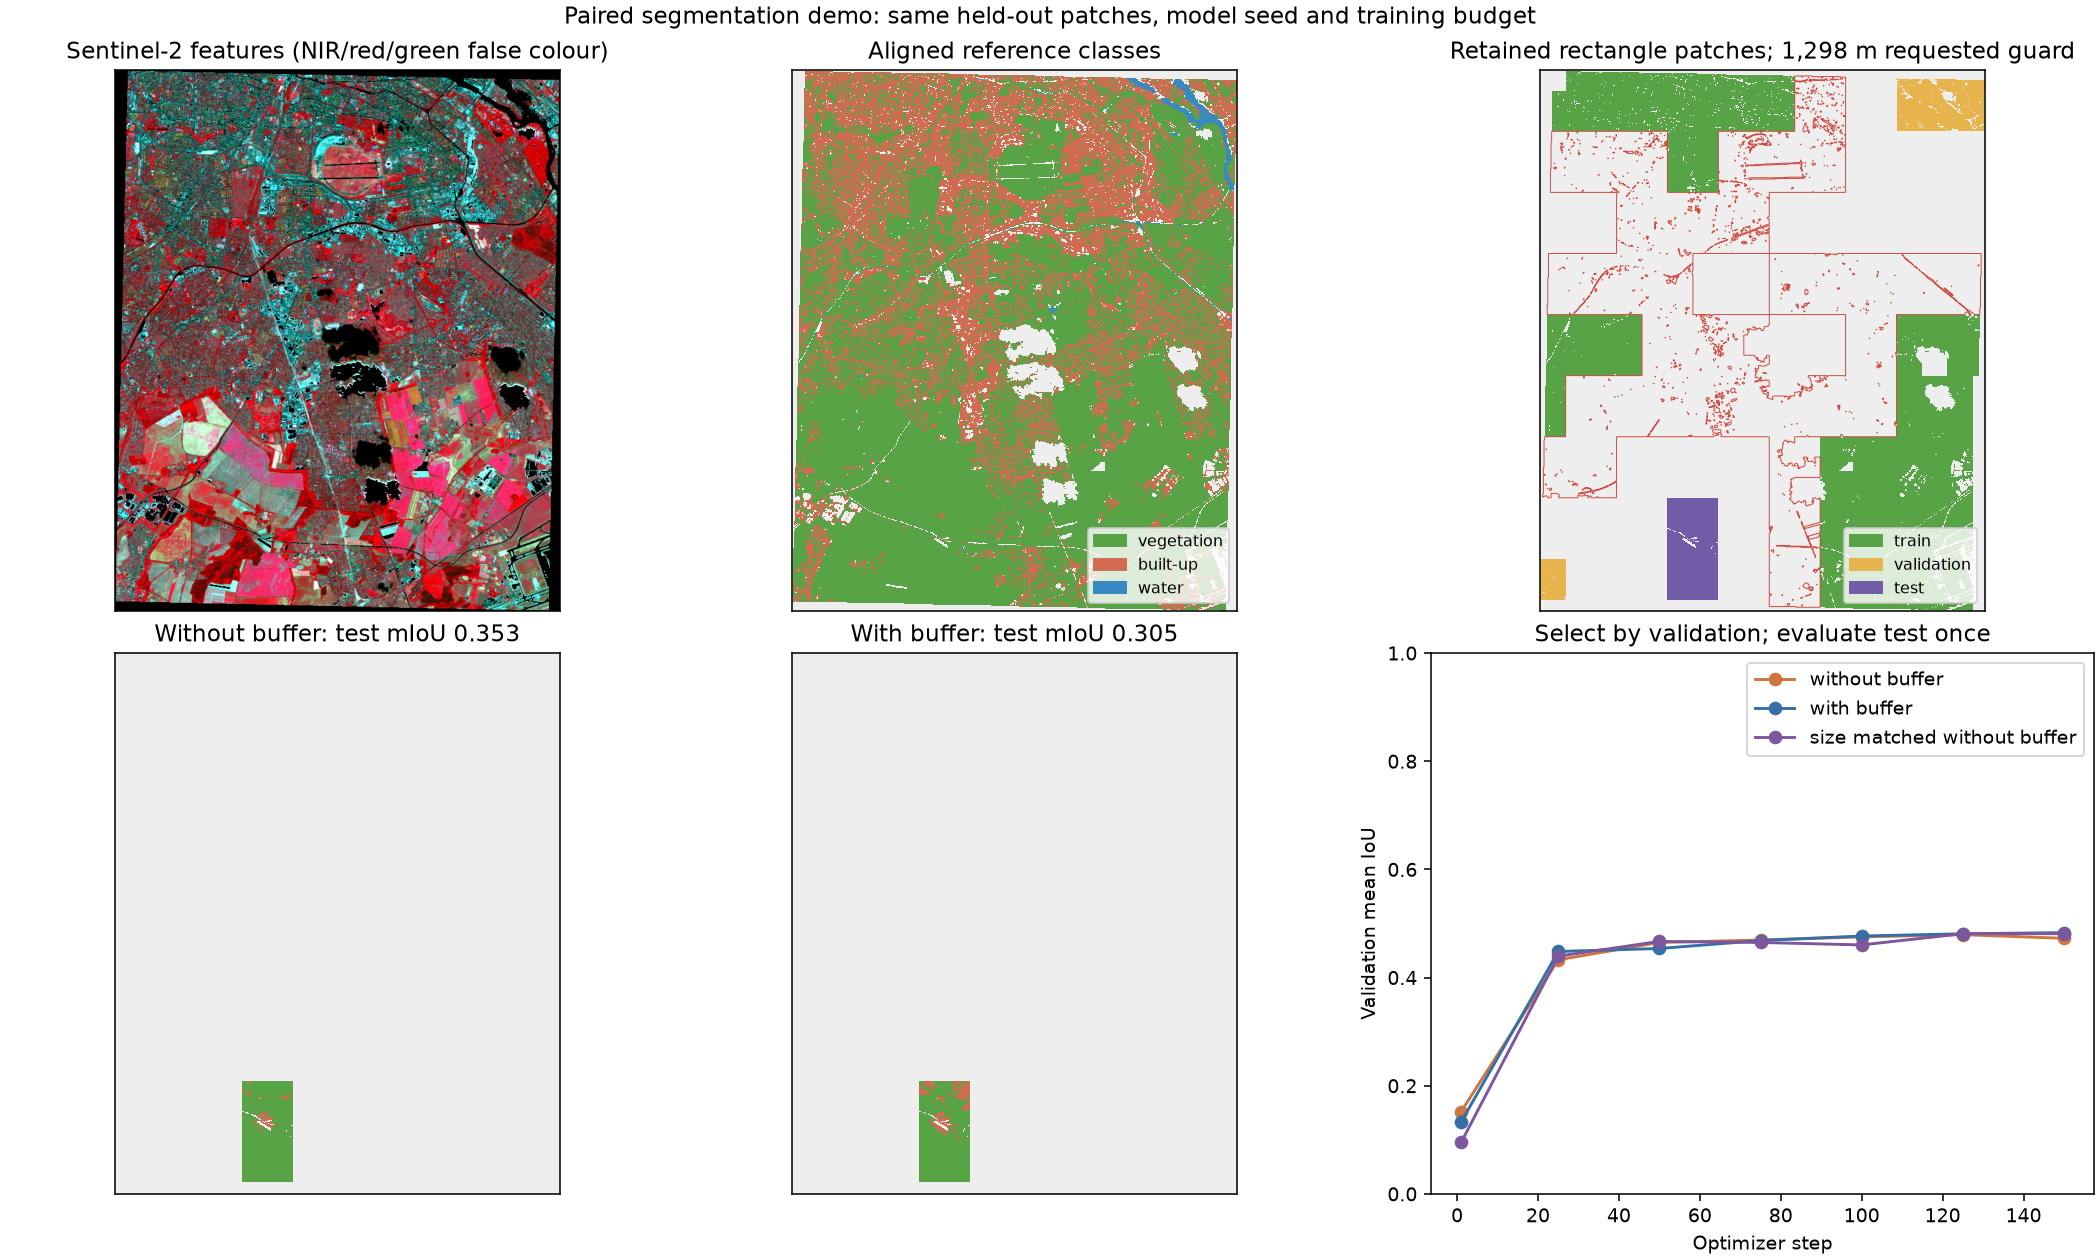

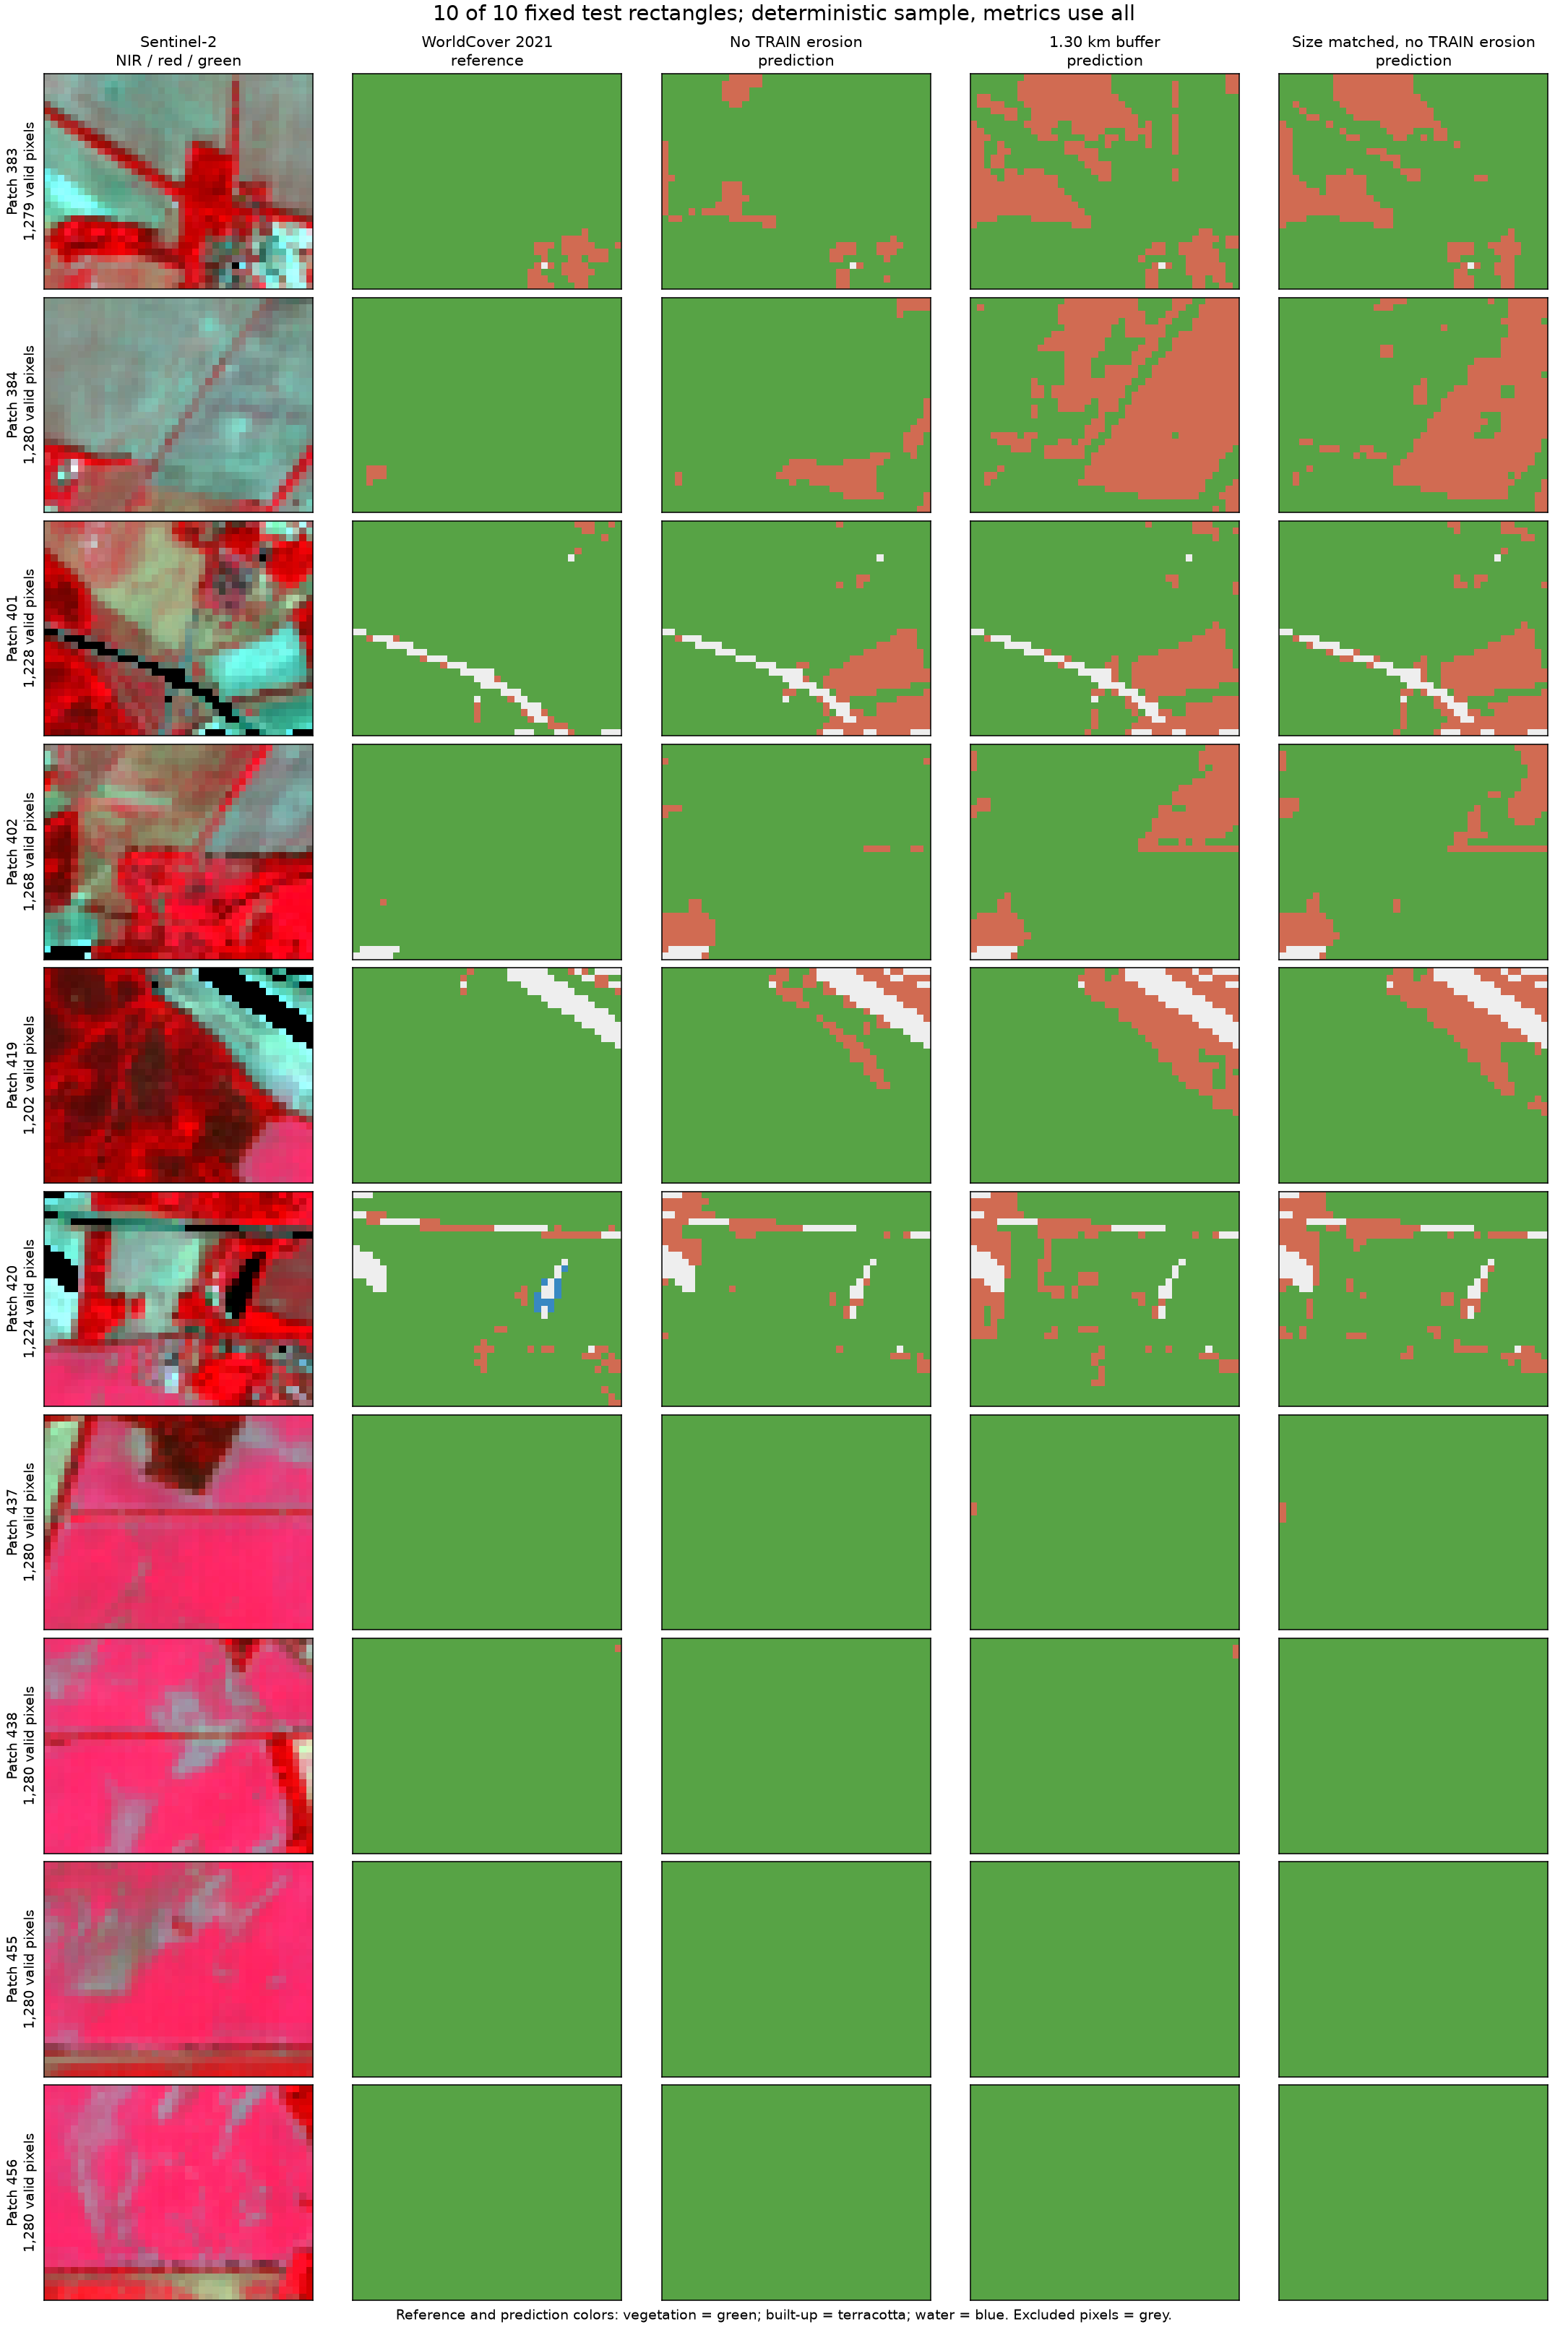

The montage shows a deterministic subset of at most 16 test patches; all metrics use every held-out test pixel.

In [10]:
display(JSON({"model":segmentation_report["model"],"controls":segmentation_report["controls"],
              "label_provenance":segmentation_report["label_provenance"],
              "training_seconds":segmentation_report["elapsed_seconds"],
              "montage_sampling":segmentation_report.get("montage_sampling")}))
display(Image(filename=str(BENCHMARK_DIR / segmentation_report["artifacts"]["comparison"])))

if "test_patch_montage" in segmentation_report["artifacts"]:
    display(Image(filename=str(BENCHMARK_DIR / segmentation_report["artifacts"]["test_patch_montage"])))
    display(Markdown("The montage shows a deterministic subset of at most 16 test patches; all metrics use every held-out test pixel."))


## Observed scores, per-class IoU and measured separation

The table reports actual trained models on identical held-out locations. The first condition removes the **training-side** erosion only; the validation/test side remains eroded. Its measured train–test distance can already exceed the requested buffer. The second condition uses symmetric erosion. Neither condition is labelled "leaky" or "independent".

The size-matched control helps expose the training-volume confound; it cannot isolate every change in class mix or spatial support. A lower buffered score can be an honest consequence of changing support and reducing the training pool. All metrics cover every held-out test pixel, even when the prediction montage displays a deterministic subset.


In [11]:
conditions=segmentation_report["conditions"]
rows=["| Condition | Train patches | Labelled train pixels | Test mIoU | Test accuracy | Min train–test patch-edge gap (m) |",
      "| --- | ---: | ---: | ---: | ---: | ---: |"]
for name,result in conditions.items():
    rows.append(f"| {CONDITION_LABELS.get(name,name)} | {result['training_patch_count']} | {result['training_labelled_pixel_count']:,} | "
                f"{result['test']['mean_iou']:.4f} | {result['test']['pixel_accuracy']:.4f} | "
                f"{result['minimum_train_test_patch_edge_distance_m']:.1f} |")
display(Markdown("\n".join(rows)))
class_rows=["| Class | Test reference pixels | "+" | ".join(CONDITION_LABELS.get(name,name) for name in conditions)+" |",
            "| --- | ---: | "+" | ".join("---:" for _ in conditions)+" |"]
for i,name in enumerate(segmentation_report["class_names"]):
    class_rows.append(f"| {name} | {conditions['without_buffer']['test']['reference_class_counts'][i]:,} | "+
        " | ".join("missing" if result['test']['per_class_iou'][i] is None else f"{result['test']['per_class_iou'][i]:.4f}"
                   for result in conditions.values())+" |")
display(Markdown("\n".join(class_rows)))
display(JSON({"retained_training_labelled_fraction":segmentation_report["retained_training_labelled_fraction"],
              "conditions":{name:{key:result[key] for key in (
                  "selected_step","selected_validation_mean_iou","labelled_class_counts",
                  "minimum_train_validation_patch_edge_distance_m","minimum_train_test_patch_edge_distance_m","test")}
                  for name,result in conditions.items()},
              "interpretation":segmentation_report["interpretation"]}))


| Condition | Train patches | Labelled train pixels | Test mIoU | Test accuracy | Min train–test patch-edge gap (m) |
| --- | ---: | ---: | ---: | ---: | ---: |
| without training erosion (fixed eroded held-outs) | 306 | 355,160 | 0.3527 | 0.9502 | 1600.0 |
| with symmetric training erosion | 124 | 139,081 | 0.3055 | 0.8579 | 3200.0 |
| size-matched, without training erosion | 124 | 142,756 | 0.3259 | 0.8948 | 1600.0 |

| Class | Test reference pixels | without training erosion (fixed eroded held-outs) | with symmetric training erosion | size-matched, without training erosion |
| --- | ---: | ---: | ---: | ---: |
| vegetation | 12,429 | 0.9502 | 0.8568 | 0.8944 |
| built-up | 161 | 0.1079 | 0.0597 | 0.0832 |
| water | 11 | 0.0000 | 0.0000 | 0.0000 |

<IPython.core.display.JSON object>

The measured symmetric buffer increases exclusion around split boundaries. The paired baseline restores training support while retaining the held-out erosion, so its distance must be read from the report. Compare both conditions with the size-matched control before interpreting a score difference. **The score gap cannot be attributed to leakage alone**, and no accuracy gain from buffering is assumed.

One AOI, one acquisition and one chosen class-covering split provide a demonstration rather than an estimate of generalization uncertainty. Report any rare-class failures, repeat across seeds/regions/seasons, and use independent labels for operational evaluation. WorldCover-derived scores measure reference-map agreement rather than independently surveyed accuracy.


## MCP tool contract

Four tools expose measurements and patch planning: `evaluate_sentinel2_autocorrelation`, `evaluate_spatial_autocorrelation`, `plan_sentinel2_split`, and `plan_spatial_split`. Planning accepts `patch_layout="reference_blocks"`, configurable `split_ratios`, `patch_size_pixels`, `block_size_pixels`, `edge_policy`, `seed_candidates` and `max_nan_fraction`. It exports raw candidates, buffered and paired training-restored masks, plus patch records. Mask values are `0=excluded`, `1=train`, `2=validation`, `3=test`.

The offline extraction can use `class_labels` and require class coverage. The server's imagery-only MCP call does not receive reference classes, so its seed search uses geometric support and can select a different seed. The optional model runner remains separate from the MCP server; PyTorch is not required by the four tools.

The following cell discovers the actual schemas and invokes the new block-based planner on real 2021 B05 pixels. It uses the same ratios and geometry settings, without claiming that an imagery-only split reproduces a class-aware offline selection.


In [12]:
from mcp import ClientSession
from mcp.client.stdio import StdioServerParameters,stdio_client
server_parameters=StdioServerParameters(command=sys.executable,
    args=[str(TOOL_ROOT / "server.py"),"--transport","stdio"])
async with stdio_client(server_parameters) as (read,write):
    async with ClientSession(read,write) as session:
        await session.initialize()
        tools=await session.list_tools()
        display(JSON({tool.name:tool.inputSchema for tool in tools.tools}))
        result=await session.call_tool("plan_spatial_split",{
            "raster_path":str(feature_path),"band_index":1,"buffer_m":LAG_M,"lag_m":LAG_M,
            "patch_layout":PATCH_LAYOUT,"patch_size_pixels":PATCH_SIZE_PIXELS,
            "block_size_pixels":BLOCK_SIZE_PIXELS,"edge_policy":EDGE_POLICY,
                  "split_ratios":SPLIT_RATIOS,
            "seed_candidates":SEED_CANDIDATES,"max_nan_fraction":MAX_NAN_FRACTION,
            "seed":SPLIT_SEED,**VARIOGRAM_OPTIONS})
        if result.isError: raise RuntimeError(result)
        mcp_plan=json.loads(next(block.text for block in result.content if block.type=="text"))
        if mcp_plan.get("status")!="ok": raise RuntimeError(mcp_plan)
        display(JSON({key:mcp_plan[key] for key in (
            "schema_version","method","patch_layout","patch_size_pixels","block_size_pixels","edge_policy",
            "selected_seed","seed_search","requested_split_ratios","n_candidate_patches","patch_counts",
            "paired_comparison","buffer_autocorrelation","splits","spatial_diagnostics","artifacts")
            if key in mcp_plan}))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## Could EVE obtain imagery through GIS MCP?

**Yes, conditionally.** The documented [`download_satellite_imagery`](https://gis-mcp.com/data-gathering/satellite_imagery/) tool can return a numeric GeoTIFF path for Sentinel-2. A deployed GIS MCP server must first be registered with EVE; the documentation URL is not a tool endpoint. The inspected EVE account has no GIS MCP server enabled, so **GIS acquisition has not been tested here**. Actual imagery in this notebook comes from public Planetary Computer STAC through this project's reader.

Request B05 plus SCL on their common 20 m grid, verify the actual returned scene/date/assets, crop to the AOI, apply processing-baseline reflectance calibration and SCL cloud/shadow/nodata masking, and preserve a projected metre grid. The audited GIS writer does not apply radiometric calibration or preserve scale/offset metadata. It cannot directly stack 10 m B03/B04/B08 with 20 m B05/SCL: align the extra bands separately. Search fallbacks can relax constraints, and scene cloud percentage is not an AOI mask.

Transfer the resulting file or use shared storage before handing its path to `evaluate_spatial_autocorrelation` and `plan_spatial_split`. A path local to the GIS server is not automatically readable by the planner. The source-audited contract below records these requirements and the transport/download route; it is not evidence of an executed GIS integration.


In [13]:
gis_contract_path=ARTIFACTS / "gis_mcp_contract.json"
if gis_contract_path.exists():
    display(JSON(json.loads(gis_contract_path.read_text())))


<IPython.core.display.JSON object>

## Reference parity and live EVE evidence

The reference artifacts compare both the variogram calculations and the patch helpers with frozen checkpoint `ac7dfc6`. The patch comparison extracts functions from the actual upstream source and records the source hashes plus the explicit rectangular, edge-extension and quality-filtering adaptations. Gateway discovery documents the actual enabled EVE services. The latest live EVE replay verified schema **0.4.0**, reference-block geometry and the requested 70%/10%/20% ratios. The model/tool trace and machine-computed reports identify their version; older successful traces do not validate later implementations. The current live MCP replay evaluates the cached actual 2021 raster and plans its split; it does not reacquire imagery or train the CNN. The CNN comparison is a separate local CPU run on the same matched-2021 data. Earlier 2024 remote-acquisition traces are historical evidence.

The summary displays verification flags and any human review notes. Model prose can misstate numbers or overclaim leakage prevention; the numeric reports and geometry checks govern interpretation. No diagnostic proves label independence, independence in all other bands, or temporal transferability.


In [14]:
for filename in ("reference_validation.json","patch_reference_validation.json",
                 "eve_gateway_discovery.json","eve_demo.json"):
    evidence_path=ARTIFACTS / filename
    if not evidence_path.exists():
        print(f"No saved evidence: {filename}")
        continue
    evidence=json.loads(evidence_path.read_text())
    if filename in ("reference_validation.json","patch_reference_validation.json"):
        display(JSON(evidence))
    elif filename=="eve_gateway_discovery.json":
        display(JSON({"file":filename,**{key:evidence[key] for key in (
            "tested_at_utc","imagery_access_note","sentinel2_discovery_calls") if key in evidence}}))
    else:
        display(JSON({"file":filename,**{key:evidence[key] for key in (
            "tested_at_utc","model","servers","available_tool_names","verification",
            "configuration_source","input_reference","review_notes") if key in evidence}}))

eve_plan_path=ARTIFACTS / "eve_planner_report.json"
if eve_plan_path.exists():
    eve_plan=json.loads(eve_plan_path.read_text())
    display(JSON({"file":"eve_planner_report.json",**{key:eve_plan[key] for key in (
        "schema_version","method","patch_layout","patch_size_pixels","block_size_pixels","edge_policy",
        "selected_seed","requested_split_ratios","paired_comparison") if key in eve_plan},
        "validates_current_reference_block_version":(
            eve_plan.get("schema_version")==planner.SCHEMA_VERSION
            and eve_plan.get("patch_layout")=="reference_blocks" and eve_plan.get("edge_policy")=="extend")}))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## Scientific limits

Approximate **stationarity and isotropy** are assumed. Uniform angles average directional structure away. Pair differencing removes dependence on an arbitrary constant mean but **does not remove spatial trend**: trend can affect both gamma and global variance, and therefore rho. Inspect the fit, accepted pair counts and AOI structure before relying on the range. Cloud exclusions can bias the sampled subset.

Use continuous fields for the variogram. Arbitrary categorical class codes have no meaningful numeric variance; per-class indicators are possible separate analyses. The B05-derived buffer does not establish that all other bands or labels share the same spatial range. Random rectangle selection and buffer exclusions change training composition, and this demonstration does not guarantee balanced classes or operational model quality.
